<a href="https://colab.research.google.com/github/Susmitha24-06/ML_LAB_2026-27/blob/main/Diabetes_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Aim: To predict whether a person has diabetes or not using medical information such as glucose level, blood pressure, BMI, insulin and age.
This beginner-friendly project uses one CSV dataset and compares five classification algorithms. The target variable is Outcome, where 0 represents non-diabetic and 1 represents diabetic.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

Load the dataset
Upload the diabetes.csv dataset to the Google Colab Files panel before running this cell.

In [5]:

import pandas as pd

data = pd.read_csv('/content/small_diabetes_dataset-1.csv')

print(data.head())

print("\nDataset shape:", data.shape)

print("\nMissing values:\n", data.isnull().sum())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            1       85             66             29        0  26.6   
1            8      183             64              0        0  23.3   
2            1       89             66             23       94  28.1   
3            0      137             40             35      168  43.1   
4            5      116             74              0        0  25.6   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.351   31        0  
1                     0.672   32        1  
2                     0.167   21        0  
3                     2.288   33        1  
4                     0.201   30        0  

Dataset shape: (30, 9)

Missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome              

Separate input and output

In [7]:

X = data.drop('Outcome', axis=1)

y = data['Outcome']

print("Input features:", list(X.columns))

print("Output classes:", sorted(y.unique()))

Input features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Output classes: [np.int64(0), np.int64(1)]


Handle missing and invalid values
In the commonly used Pima Indians Diabetes dataset, zero values in some medical measurement columns can represent missing measurements.

In [8]:

zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

X[zero_columns] = X[zero_columns].replace(0, np.nan)

print("Missing values after cleaning:\n")
print(X.isnull().sum())

Missing values after cleaning:

Pregnancies                  0
Glucose                      0
BloodPressure                3
SkinThickness               14
Insulin                     16
BMI                          1
DiabetesPedigreeFunction     0
Age                          0
dtype: int64


Split the dataset
Split the dataset into 80% training data and 20% testing data.

In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24, 8)
Testing data: (6, 8)


Apply machine learning algorithms
In this project, five classification algorithms are used:
K-Nearest Neighbors (KNN)
Decision Tree
Logistic Regression
Random Forest
Support Vector Machine (SVM)

In [10]:

models = {
    "KNN": make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Decision Tree": make_pipeline(
        SimpleImputer(strategy='median'),
        DecisionTreeClassifier(random_state=42)
    ),

    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestClassifier(n_estimators=100, random_state=42)
    ),

    "SVM": make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        SVC()
    )
}

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    score = accuracy_score(y_test, predictions)

    results[name] = score

    print(name, "Accuracy:", round(score * 100, 2), "%")

KNN Accuracy: 66.67 %
Decision Tree Accuracy: 66.67 %
Logistic Regression Accuracy: 66.67 %
Random Forest Accuracy: 83.33 %
SVM Accuracy: 66.67 %


Compare model accuracy

             Algorithm  Accuracy
3        Random Forest  0.833333
0                  KNN  0.666667
1        Decision Tree  0.666667
2  Logistic Regression  0.666667
4                  SVM  0.666667


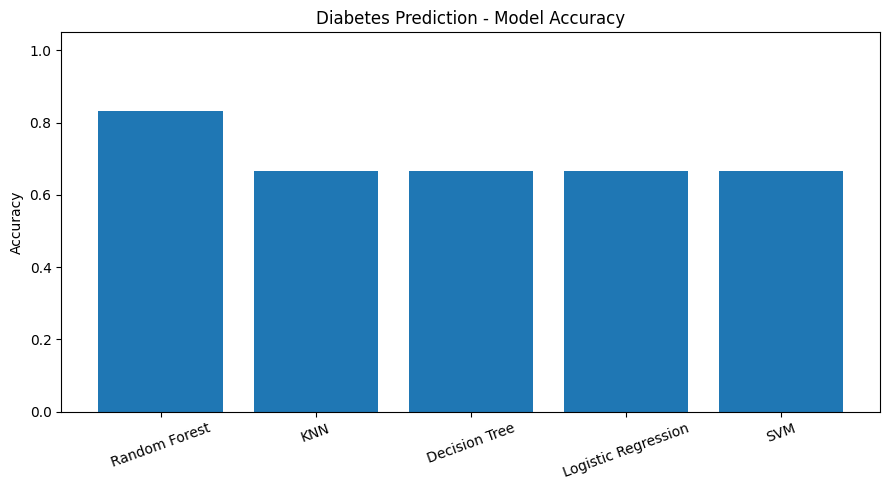

In [11]:

results_df = pd.DataFrame({
    "Algorithm": list(results.keys()),
    "Accuracy": list(results.values())
}).sort_values("Accuracy", ascending=False)

print(results_df)

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Algorithm"],
    results_df["Accuracy"]
)

plt.ylabel("Accuracy")

plt.title("Diabetes Prediction - Model Accuracy")

plt.ylim(0, 1.05)

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

Classification report for the best model

In [12]:

best_name = max(results, key=results.get)

best_model = models[best_name]

print("Best model:", best_name)

predictions = best_model.predict(X_test)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        predictions,
        zero_division=0
    )
)

Best model: Random Forest

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           1       0.75      1.00      0.86         3

    accuracy                           0.83         6
   macro avg       0.88      0.83      0.83         6
weighted avg       0.88      0.83      0.83         6



Predict diabetes for new sample conditions
Change the sample values to test another example. Values are illustrative only.

In [13]:

new_sample = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 20,
    "Insulin": 79,
    "BMI": 25.5,
    "DiabetesPedigreeFunction": 0.35,
    "Age": 30
}])

predicted_result = best_model.predict(new_sample)

if predicted_result[0] == 1:
    print("Prediction: Diabetic")
else:
    print("Prediction: Non-Diabetic")

Prediction: Diabetic


Conclusion
In this project, one diabetes dataset was used to train and compare five machine learning algorithms: KNN, Decision Tree, Logistic Regression, Random Forest and SVM.
The models were evaluated using accuracy scores and a classification report. The best-performing model was selected based on test accuracy.
The trained model predicts whether a person belongs to the diabetic or non-diabetic class based on the given medical features.
Note: This project is for educational purposes only. Its predictions are not medical diagnoses. Diabetes diagnosis requires proper medical evaluation by a qualified healthcare professional.